In [2]:
import sys
print(sys.executable)

c:\Users\Sai deepak\anaconda3\python.exe


In [3]:
%pip install pm4py

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import pm4py


print("Pandas:", pd.__version__)
print("PM4Py:", pm4py.__version__)



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




Pandas: 2.2.3
PM4Py: 2.7.23.11


In [5]:
df = pd.read_excel("../output of pandas/careflow_cleaned_events.xlsx")

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (10485, 15)
Columns: ['Case_ID', 'Activity_Name', 'Timestamp', 'Event_Order', 'Department', 'Triage_Priority', 'Shift', 'Doctor_ID', 'Event_Time', 'Arrival_Time', 'Day_Offset', 'Timestamp_Reconstructed', 'Previous_Activity', 'Previous_Time', 'Transition_Min']


,Case_ID,Activity_Name,Timestamp,Event_Order,Department,Triage_Priority,Shift,Doctor_ID,Event_Time,Arrival_Time,Day_Offset,Timestamp_Reconstructed,Previous_Activity,Previous_Time,Transition_Min
0,CF00001,Registration,20:22:00,1,General Emergency,Medium,Evening,DR006,0.848611,0.848611,0,2026-01-01 00:00:00,NaN,NaT,NaN
1,CF00001,Triage,21:39:00,2,General Emergency,Medium,Evening,DR006,0.902083,0.848611,0,2026-01-01 01:17:00,Registration,2026-01-01 00:00:00,77.0
2,CF00001,Doctor Consultation,23:12:00,3,General Emergency,Medium,Evening,DR006,0.966667,0.848611,0,2026-01-01 02:50:00,Triage,2026-01-01 01:17:00,93.0
3,CF00001,Treatment,01:02:00,4,General Emergency,Medium,Evening,DR006,0.043056,0.848611,1,2026-01-01 04:40:00,Doctor Consultation,2026-01-01 02:50:00,110.0
4,CF00001,Discharge,01:51:00,5,General Emergency,Medium,Evening,DR006,0.077083,0.848611,1,2026-01-01 05:29:00,Treatment,2026-01-01 04:40:00,49.0


In [6]:
import pandas as pd
import pm4py

df = pd.read_excel("../output of pandas/careflow_cleaned_events.xlsx")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
print(df.dtypes)
display(df.head())

Shape: (10485, 15)

Columns: ['Case_ID', 'Activity_Name', 'Timestamp', 'Event_Order', 'Department', 'Triage_Priority', 'Shift', 'Doctor_ID', 'Event_Time', 'Arrival_Time', 'Day_Offset', 'Timestamp_Reconstructed', 'Previous_Activity', 'Previous_Time', 'Transition_Min']

Data types:
Case_ID                            object
Activity_Name                      object
Timestamp                          object
Event_Order                         int64
Department                         object
Triage_Priority                    object
Shift                              object
Doctor_ID                          object
Event_Time                        float64
Arrival_Time                      float64
Day_Offset                          int64
Timestamp_Reconstructed    datetime64[ns]
Previous_Activity                  object
Previous_Time              datetime64[ns]
Transition_Min                    float64
dtype: object


,Case_ID,Activity_Name,Timestamp,Event_Order,Department,Triage_Priority,Shift,Doctor_ID,Event_Time,Arrival_Time,Day_Offset,Timestamp_Reconstructed,Previous_Activity,Previous_Time,Transition_Min
0,CF00001,Registration,20:22:00,1,General Emergency,Medium,Evening,DR006,0.848611,0.848611,0,2026-01-01 00:00:00,NaN,NaT,NaN
1,CF00001,Triage,21:39:00,2,General Emergency,Medium,Evening,DR006,0.902083,0.848611,0,2026-01-01 01:17:00,Registration,2026-01-01 00:00:00,77.0
2,CF00001,Doctor Consultation,23:12:00,3,General Emergency,Medium,Evening,DR006,0.966667,0.848611,0,2026-01-01 02:50:00,Triage,2026-01-01 01:17:00,93.0
3,CF00001,Treatment,01:02:00,4,General Emergency,Medium,Evening,DR006,0.043056,0.848611,1,2026-01-01 04:40:00,Doctor Consultation,2026-01-01 02:50:00,110.0
4,CF00001,Discharge,01:51:00,5,General Emergency,Medium,Evening,DR006,0.077083,0.848611,1,2026-01-01 05:29:00,Treatment,2026-01-01 04:40:00,49.0


In [7]:
import pandas as pd
import pm4py

# Select PM4Py-required columns
event_log_df = df[
    ["Case_ID", "Activity_Name", "Timestamp_Reconstructed"]
].copy()

# Rename columns to PM4Py standard names
event_log_df = event_log_df.rename(columns={
    "Case_ID": "case:concept:name",
    "Activity_Name": "concept:name",
    "Timestamp_Reconstructed": "time:timestamp"
})

# Ensure correct data types and remove invalid required rows
event_log_df["time:timestamp"] = pd.to_datetime(
    event_log_df["time:timestamp"], errors="coerce"
)

event_log_df = event_log_df.dropna(
    subset=["case:concept:name", "concept:name", "time:timestamp"]
)

# Sort events chronologically within each case
event_log_df = event_log_df.sort_values(
    ["case:concept:name", "time:timestamp"]
).reset_index(drop=True)

# Convert DataFrame to PM4Py event log
event_log = pm4py.convert_to_event_log(event_log_df)

print("Cases:", event_log_df["case:concept:name"].nunique())
print("Events:", len(event_log_df))
print("Activities:", event_log_df["concept:name"].nunique())
print("PM4Py event log created successfully!")

Cases: 1500
Events: 10485
Activities: 8
PM4Py event log created successfully!


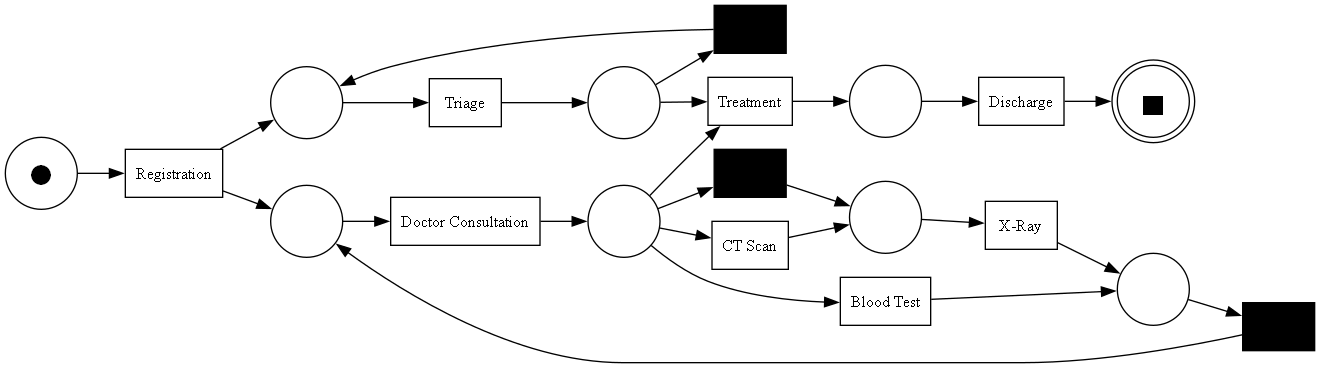

In [8]:
# Discover a process model using the Inductive Miner
import pandas as pd
import pm4py
net, initial_marking, final_marking = pm4py.discover_petri_net_inductive(
    event_log
)

# Display the process map
pm4py.view_petri_net(net, initial_marking, final_marking)

In [9]:
from collections import Counter
import pandas as pd
import pm4py

variants = pm4py.get_variants(event_log)

variant_counts = Counter({
    str(variant): len(traces)
    for variant, traces in variants.items()
})

for variant, count in variant_counts.most_common(10):
    print(f"{count} cases ({count / len(event_log) * 100:.2f}%): {variant}")

391 cases (26.07%): ('Registration', 'Triage', 'Doctor Consultation', 'Blood Test', 'Doctor Consultation', 'Treatment', 'Discharge')
342 cases (22.80%): ('Registration', 'Triage', 'Doctor Consultation', 'Treatment', 'Discharge')
290 cases (19.33%): ('Registration', 'Triage', 'Doctor Consultation', 'X-Ray', 'Doctor Consultation', 'Treatment', 'Discharge')
156 cases (10.40%): ('Registration', 'Triage', 'Doctor Consultation', 'X-Ray', 'Triage', 'Doctor Consultation', 'Treatment', 'Discharge')
146 cases (9.73%): ('Registration', 'Triage', 'Doctor Consultation', 'Blood Test', 'Doctor Consultation', 'X-Ray', 'Doctor Consultation', 'Treatment', 'Discharge')
110 cases (7.33%): ('Registration', 'Triage', 'Doctor Consultation', 'Blood Test', 'Triage', 'Doctor Consultation', 'Treatment', 'Discharge')
31 cases (2.07%): ('Registration', 'Triage', 'Doctor Consultation', 'CT Scan', 'X-Ray', 'Doctor Consultation', 'Treatment', 'Discharge')
22 cases (1.47%): ('Registration', 'Triage', 'Doctor Consultat

In [10]:
from collections import Counter

transitions = Counter()

for case_id, group in df.groupby("Case_ID", sort=False):
    group = group.sort_values("Event_Order")
    activities = group["Activity_Name"].tolist()

    for i in range(len(activities) - 1):
        transitions[(activities[i], activities[i + 1])] += 1

transition_df = pd.DataFrame([
    {
        "From Activity": source,
        "To Activity": target,
        "Frequency": count
    }
    for (source, target), count in transitions.most_common()
])

transition_df["Percentage"] = (
    transition_df["Frequency"] / df["Case_ID"].nunique() * 100
).round(2)

display(transition_df.head(19))

,From Activity,To Activity,Frequency,Percentage
0,Triage,Doctor Consultation,1788,119.20
1,Registration,Triage,1500,100.00
2,Doctor Consultation,Treatment,1500,100.00
3,Treatment,Discharge,1500,100.00
4,Doctor Consultation,Blood Test,659,43.93
5,Doctor Consultation,X-Ray,592,39.47
6,Blood Test,Doctor Consultation,549,36.60
7,X-Ray,Doctor Consultation,479,31.93
8,X-Ray,Triage,178,11.87
9,Blood Test,Triage,110,7.33


In [11]:
import pandas as pd

# Load cleaned event log


rows = []

for (source, target), group in df.groupby(
    ["Previous_Activity", "Activity_Name"]
):
    if pd.isna(source):
        continue

    rows.append({
        "From Activity": source,
        "To Activity": target,
        "Transition Count": len(group),
        "Unique Cases": group["Case_ID"].nunique()
    })

transition_analysis = pd.DataFrame(rows)

total_cases = df["Case_ID"].nunique()

transition_analysis["Case Percentage"] = (
    transition_analysis["Unique Cases"] / total_cases * 100
).round(2)

transition_analysis = transition_analysis.sort_values(
    "Transition Count", ascending=False
).reset_index(drop=True)

display(transition_analysis.head(15))

,From Activity,To Activity,Transition Count,Unique Cases,Case Percentage
0,Triage,Doctor Consultation,1788,1500,100.00
1,Registration,Triage,1500,1500,100.00
2,Doctor Consultation,Treatment,1500,1500,100.00
3,Treatment,Discharge,1500,1500,100.00
4,Doctor Consultation,Blood Test,659,659,43.93
5,Doctor Consultation,X-Ray,592,592,39.47
6,Blood Test,Doctor Consultation,549,549,36.60
7,X-Ray,Doctor Consultation,479,479,31.93
8,X-Ray,Triage,178,178,11.87
9,Blood Test,Triage,110,110,7.33


In [12]:
from pathlib import Path

output_dir = Path("../output of pandas")
output_dir.mkdir(parents=True, exist_ok=True)

transition_analysis.to_excel(
    output_dir / "careflow_pm4py_transition_analysis.xlsx",
    index=False
)

print("Transition analysis saved successfully!")

Transition analysis saved successfully!


In [13]:
import pandas as pd

df["Transition_Min"] = pd.to_numeric(
    df["Transition_Min"], errors="coerce"
)

performance = df.groupby(
    ["Previous_Activity", "Activity_Name"]
).agg(
    Event_Count=("Case_ID", "size"),
    Unique_Cases=("Case_ID", "nunique"),
    Average_Time_Min=("Transition_Min", "mean"),
    Median_Time_Min=("Transition_Min", "median")
).reset_index()

performance = performance.dropna(
    subset=["Previous_Activity"]
)

performance[["Average_Time_Min", "Median_Time_Min"]] = (
    performance[["Average_Time_Min", "Median_Time_Min"]].round(2)
)

display(performance.sort_values(
    "Average_Time_Min", ascending=False
).head(15))

,Previous_Activity,Activity_Name,Event_Count,Unique_Cases,Average_Time_Min,Median_Time_Min
6,Doctor Consultation,X-Ray,592,592,112.46,105.0
3,Doctor Consultation,Blood Test,659,659,112.15,107.0
4,Doctor Consultation,CT Scan,65,65,108.38,99.0
2,CT Scan,X-Ray,65,65,100.20,89.0
0,Blood Test,Doctor Consultation,549,549,92.02,85.0
9,Triage,Doctor Consultation,1788,1500,90.57,81.0
10,X-Ray,Doctor Consultation,479,479,85.78,74.0
5,Doctor Consultation,Treatment,1500,1500,57.99,53.0
8,Treatment,Discharge,1500,1500,48.49,49.0
1,Blood Test,Triage,110,110,48.45,44.0


In [ ]:
from pathlib import Path

output_dir = Path("../output of pandas")
output_dir.mkdir(parents=True, exist_ok=True)

performance.to_excel(
    output_dir / "careflow_pm4py_performance_analysis.xlsx",
    index=False
)

print("Performance analysis saved successfully!")